### Librerias

In [1]:
# Importar el dataset al notebook
import re
from datetime import date
from bs4 import BeautifulSoup
from urllib.parse import urljoin
from pathlib import Path
import requests
import pandas as pd

# Analisis EDA
import numpy as np
import matplotlib.pyplot as plt


### Variables de entorno

In [2]:
# Fechas de inicio y fin del dataset
inicio = date(2023, 1, 1)
fin = date(2026, 9, 30)

# Pagina web de donde se obtendrán los datos
pagina = "https://mibici.net/es/datos-abiertos/"

# Carga de datos al notebook

In [3]:
sesion = requests.Session()
sesion.headers.update({
    "User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 Chrome/131.0.0.0 Safari/537.36",
    "Accept": "text/html,application/xhtml+xml,application/xml;q=0.9,*/*;q=0.8",
    "Accept-Language": "es-MX,es;q=0.9,en;q=0.8",
})

respuesta = sesion.get(pagina, timeout=30)
respuesta.raise_for_status()

In [4]:
carpeta = Path("mibici_csv")
carpeta.mkdir(exist_ok=True)

soup = BeautifulSoup(respuesta.text, "html.parser")

In [5]:
for a in soup.select('a[href$=".csv"]'):
    url = urljoin(pagina, a["href"])
    nombre = url.rsplit("/", 1)[-1]

    coincidencia = re.search(r"datos_abiertos_(\d{4})_(\d{2})\.csv$", nombre)
    if not coincidencia:
        print("Omitido:", nombre)
        continue

    anio, mes = map(int, coincidencia.groups())
    mes_inicio = date(anio, mes, 1)
    siguiente_mes = date(anio + (mes == 12), mes % 12 + 1, 1)
    mes_fin = date.fromordinal(siguiente_mes.toordinal() - 1)
    
    destino = carpeta / nombre
    if mes_inicio <= fin and mes_fin >= inicio:    
        for intento in range(5):
            try:
                with sesion.get(
                    url,
                    timeout=(20, 180),
                    stream=True
                ) as r:
                    r.raise_for_status()

                    with open(destino, "wb") as archivo:
                        for bloque in r.iter_content(chunk_size=1024 * 1024):
                            if bloque:
                                archivo.write(bloque)

                print("Descargado:", nombre)
                break

            except requests.exceptions.RequestException:
                destino.unlink(missing_ok=True)

                if intento == 4:
                    raise

                print(f"Descarga interrumpida; reintentando ({intento + 1}/4)…")
                time.sleep(2 ** intento)

Omitido: nomenclatura_2026_09.csv
Omitido: datos_abiertos_2016_01-1.csv
Omitido: datos_abiertos_2017_04-1.csv
Descargado: datos_abiertos_2023_01.csv
Descargado: datos_abiertos_2023_02.csv
Descargado: datos_abiertos_2023_03.csv
Descargado: datos_abiertos_2023_04.csv
Descargado: datos_abiertos_2023_05.csv
Descargado: datos_abiertos_2023_06.csv
Descargado: datos_abiertos_2023_07.csv
Descargado: datos_abiertos_2023_08.csv
Descargado: datos_abiertos_2023_09.csv
Descargado: datos_abiertos_2023_10.csv
Descargado: datos_abiertos_2023_11.csv
Descargado: datos_abiertos_2023_12.csv
Descargado: datos_abiertos_2024_01.csv
Descargado: datos_abiertos_2024_02.csv
Descargado: datos_abiertos_2024_03.csv
Descargado: datos_abiertos_2024_04.csv
Descargado: datos_abiertos_2024_05.csv
Descargado: datos_abiertos_2024_06.csv
Descargado: datos_abiertos_2024_07.csv
Descargado: datos_abiertos_2024_08.csv
Descargado: datos_abiertos_2024_09.csv
Descargado: datos_abiertos_2024_10.csv
Descargado: datos_abiertos_2024_

In [6]:
carpeta = Path("mibici_csv")
archivos = sorted(carpeta.glob("datos_abiertos_*.csv"))

In [7]:
dataframes = []

for archivo in archivos:
    try:
        tabla = pd.read_csv(archivo, encoding="latin-1")
        print(archivo.name, "latin-1")
    except UnicodeDecodeError:
        try:
            tabla = pd.read_csv(archivo, encoding="UTF-8")
            print(archivo.name, "UTF-8")
        except UnicodeDecodeError:
            print(archivo.name, "necesita otra codificación")
            continue

    dataframes.append(tabla)

df = pd.concat(dataframes, ignore_index=True)

datos_abiertos_2023_01.csv latin-1
datos_abiertos_2023_02.csv latin-1
datos_abiertos_2023_03.csv latin-1
datos_abiertos_2023_04.csv latin-1
datos_abiertos_2023_05.csv latin-1
datos_abiertos_2023_06.csv latin-1
datos_abiertos_2023_07.csv latin-1
datos_abiertos_2023_08.csv latin-1
datos_abiertos_2023_09.csv latin-1
datos_abiertos_2023_10.csv latin-1
datos_abiertos_2023_11.csv latin-1
datos_abiertos_2023_12.csv latin-1
datos_abiertos_2024_01.csv latin-1
datos_abiertos_2024_02.csv latin-1
datos_abiertos_2024_03.csv latin-1
datos_abiertos_2024_04.csv latin-1
datos_abiertos_2024_05.csv latin-1
datos_abiertos_2024_06.csv latin-1
datos_abiertos_2024_07.csv latin-1
datos_abiertos_2024_08.csv latin-1
datos_abiertos_2024_09.csv latin-1
datos_abiertos_2024_10.csv latin-1
datos_abiertos_2024_11.csv latin-1
datos_abiertos_2024_12.csv latin-1
datos_abiertos_2025_01.csv latin-1
datos_abiertos_2025_02.csv latin-1
datos_abiertos_2025_03.csv latin-1
datos_abiertos_2025_04.csv latin-1
datos_abiertos_2025_

# Descripción de la estructura de los datos

Primeros 5 registros del conjunto de datos

In [8]:
df.head()

,Viaje_Id,Usuario_Id,Genero,Año_de_nacimiento,Inicio_del_viaje,Fin_del_viaje,Origen_Id,Destino_Id,AÃ±o_de_nacimiento,A}äe_nacimiento
0,26751198,1350606,M,1983.0,2023-01-01 00:00:41,2023-01-01 00:26:52,154,50,NaN,NaN
1,26751199,15163,M,1986.0,2023-01-01 00:04:48,2023-01-01 00:07:46,64,79,NaN,NaN
2,26751200,1534764,M,1987.0,2023-01-01 00:06:49,2023-01-01 00:17:36,35,12,NaN,NaN
3,26751201,1240140,M,1996.0,2023-01-01 00:08:05,2023-01-01 00:09:00,35,35,NaN,NaN
4,26751202,1732214,M,1969.0,2023-01-01 00:09:14,2023-01-01 00:14:57,54,171,NaN,NaN


Ultimos 5 registros del conjunto de datos

In [9]:
df.tail()

,Viaje_Id,Usuario_Id,Genero,Año_de_nacimiento,Inicio_del_viaje,Fin_del_viaje,Origen_Id,Destino_Id,AÃ±o_de_nacimiento,A}äe_nacimiento
16833128,46255554,116275,F,NaN,2026-09-30 23:57:23,2026-09-30 23:59:46,43,44,1990.0,NaN
16833129,46255556,4621160,M,NaN,2026-09-30 23:59:13,2026-10-01 00:04:17,210,413,1970.0,NaN
16833130,46255556,4621160,M,NaN,2026-09-30 23:59:13,2026-10-01 00:04:17,210,413,1970.0,NaN
16833131,46255557,4560372,M,NaN,2026-09-30 23:59:32,2026-10-01 00:06:16,157,271,1987.0,NaN
16833132,46255558,4026751,M,NaN,2026-09-30 23:59:48,2026-10-01 00:13:58,78,233,2000.0,NaN


Significado de las variables:
1. Viaje_Id: Identificador del evento viaje
2. Usuario_Id: Identificador del usuario que realizó el viaje
3. Genero: Genero del usuario
4. Año_de_nacimiento: Año de nacimiento del usuario
5. Inicio_del_viaje: Fecha y hora del inicio del viaje
6. Fin_del_viaje: Fecha y hora del fin del viaje
7. Origen_Id: Identificador del lugar de inicio de la ruta del usuario
8. Destino_Id: Identificafor del lugar de cierre de la ruta del usuario
9. Año de nacimiento: Año de nacimiento del usuario

In [10]:
print(f"Registros: {df.shape[0]}, Variables: {df.shape[1]}")

print("\nTipos de variables:")
print(df.dtypes)

Registros: 16833133, Variables: 10

Tipos de variables:
Viaje_Id                int64
Usuario_Id              int64
Genero                    str
Año_de_nacimiento     float64
Inicio_del_viaje          str
Fin_del_viaje             str
Origen_Id               int64
Destino_Id              int64
AÃ±o_de_nacimiento    float64
A}äe_nacimiento       float64
dtype: object


# Análisis exploratorio de los datos (EDA)

El dataset original cuenta con 8 campos; sin embargo, debido a temas de formato, se generaron las dos columnas "AÃ±o_de_nacimiento"	y "A}äe_nacimiento". Por ello decidimos fucionar estas columnas con la columna pertinente al dataser original

In [11]:
for columna in ["AÃ±o_de_nacimiento", "A}äe_nacimiento"]:
    df["Año_de_nacimiento"] = df["Año_de_nacimiento"].fillna(df[columna])

df.drop(columns=["AÃ±o_de_nacimiento", "A}äe_nacimiento"], inplace=True)

In [12]:
df.head()

,Viaje_Id,Usuario_Id,Genero,Año_de_nacimiento,Inicio_del_viaje,Fin_del_viaje,Origen_Id,Destino_Id
0,26751198,1350606,M,1983.0,2023-01-01 00:00:41,2023-01-01 00:26:52,154,50
1,26751199,15163,M,1986.0,2023-01-01 00:04:48,2023-01-01 00:07:46,64,79
2,26751200,1534764,M,1987.0,2023-01-01 00:06:49,2023-01-01 00:17:36,35,12
3,26751201,1240140,M,1996.0,2023-01-01 00:08:05,2023-01-01 00:09:00,35,35
4,26751202,1732214,M,1969.0,2023-01-01 00:09:14,2023-01-01 00:14:57,54,171


In [13]:
df.tail()

,Viaje_Id,Usuario_Id,Genero,Año_de_nacimiento,Inicio_del_viaje,Fin_del_viaje,Origen_Id,Destino_Id
16833128,46255554,116275,F,1990.0,2026-09-30 23:57:23,2026-09-30 23:59:46,43,44
16833129,46255556,4621160,M,1970.0,2026-09-30 23:59:13,2026-10-01 00:04:17,210,413
16833130,46255556,4621160,M,1970.0,2026-09-30 23:59:13,2026-10-01 00:04:17,210,413
16833131,46255557,4560372,M,1987.0,2026-09-30 23:59:32,2026-10-01 00:06:16,157,271
16833132,46255558,4026751,M,2000.0,2026-09-30 23:59:48,2026-10-01 00:13:58,78,233


### Descripción estadística de las variables

In [14]:
display(df.describe(include='all').T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Viaje_Id,16833133.0,NaN,NaN,NaN,36538608.594573,5617914.933297,26751198.0,31688512.0,36559320.0,41389907.0,46255558.0
Usuario_Id,16833133.0,NaN,NaN,NaN,2008613.284016,1563845.669299,102.0,556110.0,1654620.0,3371110.0,5006315.0
Genero,16721823,2,M,12157995,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Año_de_nacimiento,16822153.0,NaN,NaN,NaN,1989.940441,14.682584,199.0,1984.0,1993.0,1998.0,2023.0
Inicio_del_viaje,16833133,13993215,28/10/2024 18:08,60,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Fin_del_viaje,16833133,13994953,24/09/2024 18:21,49,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Origen_Id,16833133.0,NaN,NaN,NaN,152.145248,111.065118,2.0,51.0,155.0,253.0,519.0
Destino_Id,16833133.0,NaN,NaN,NaN,153.352102,113.666965,2.0,51.0,154.0,257.0,519.0


Decidimos ajustar el tipo de dato de las variables Viaje_Id, Usuario_Id, Año_de_nacimiento, Origen_Id y Destino_Id ya que en su mayoria son identificadores o un dato categorico como lo es el año de nacimiento y nos funciona más que tengan el tipo "str" para realizar el analisis pertinente.

In [15]:
df["Viaje_Id"] = df["Viaje_Id"].astype(str)
df["Usuario_Id"] = df["Usuario_Id"].astype(str)
df["Año_de_nacimiento"] = df["Año_de_nacimiento"].astype(str)
df["Origen_Id"] = df["Origen_Id"].astype(str)
df["Destino_Id"] = df["Destino_Id"].astype(str)

In [16]:
display(df.describe(include='all').T)

,count,unique,top,freq
Viaje_Id,16833133,16832375,45705948,2
Usuario_Id,16833133,60245,501066,12214
Genero,16721823,2,M,12157995
Año_de_nacimiento,16822153,82,1996.0,898478
Inicio_del_viaje,16833133,13993215,28/10/2024 18:08,60
Fin_del_viaje,16833133,13994953,24/09/2024 18:21,49
Origen_Id,16833133,473,51,354118
Destino_Id,16833133,473,51,437683


Tras no haber variables numéricas, saltamos directamente al análisis de las variables categóricas

# Análisis de variables categóricas

C:\Users\erick\AppData\Local\Temp\ipykernel_15224\208324980.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = df.select_dtypes(


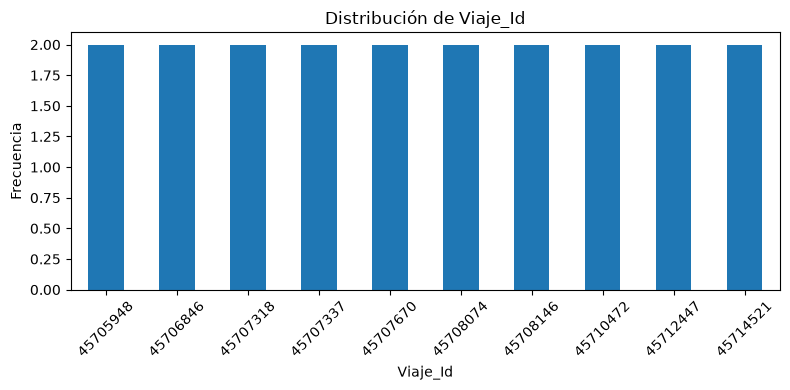

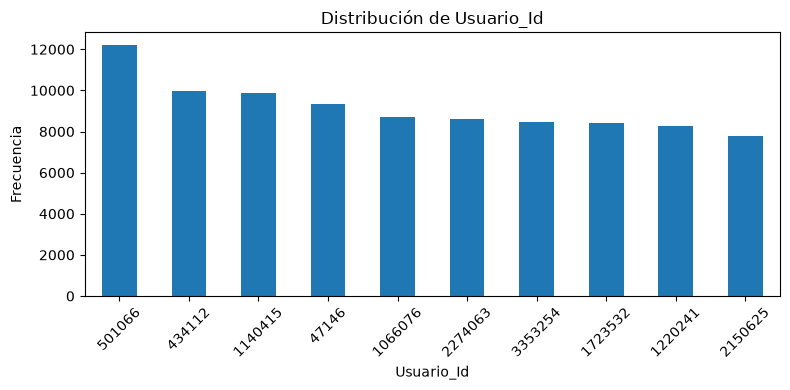

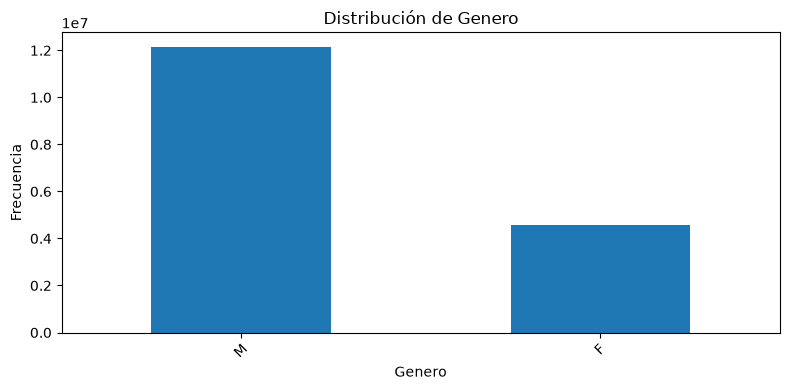

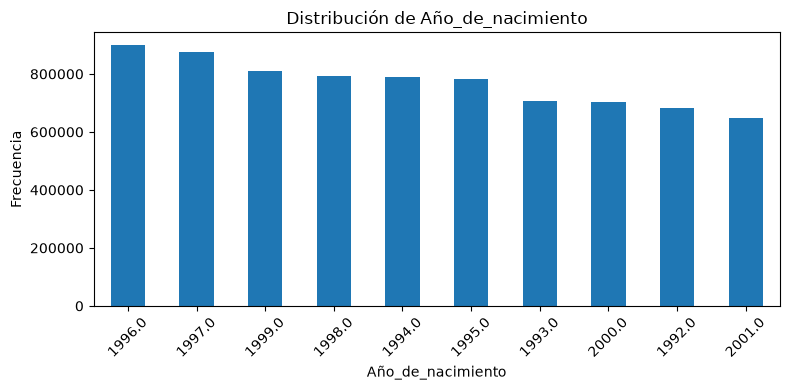

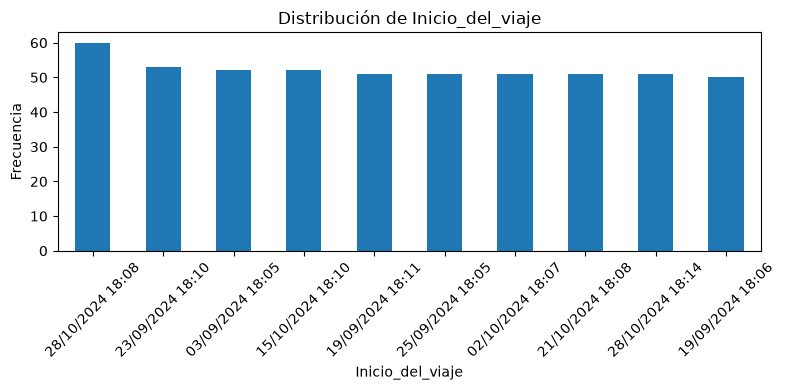

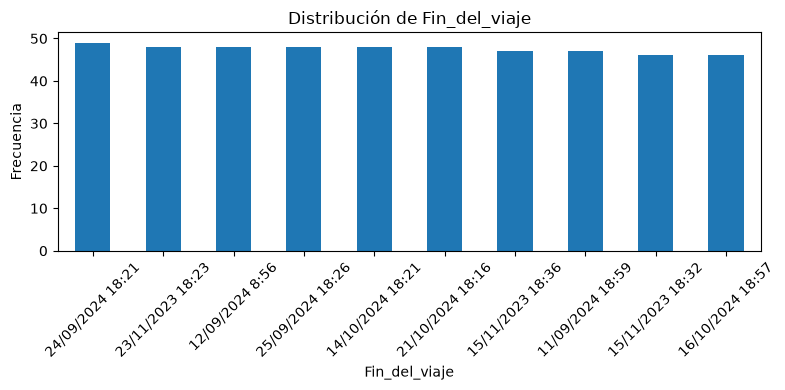

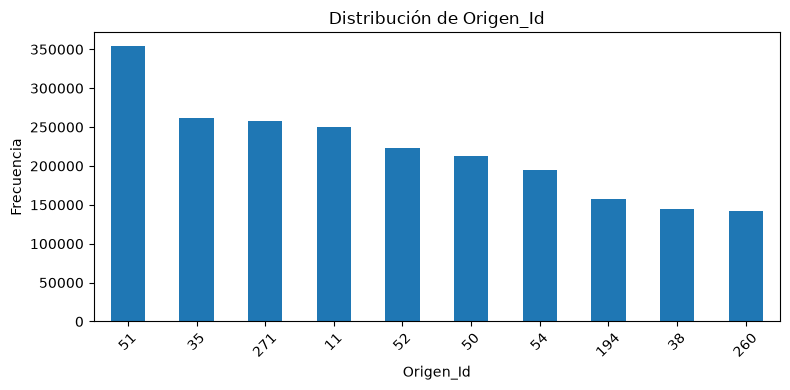

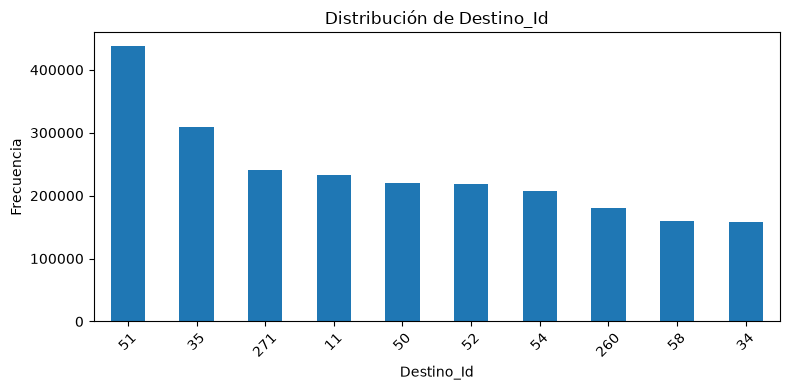

In [17]:
categorical_cols = df.select_dtypes(
    include=["object", "category", "bool"]
).columns

for col in categorical_cols:

    counts = df[col].value_counts().head(10)

    plt.figure(figsize=(8, 4))

    counts.plot(kind="bar")

    plt.xlabel(col)
    plt.ylabel("Frecuencia")
    plt.title(f"Distribución de {col}")

    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

### Valores faltantes

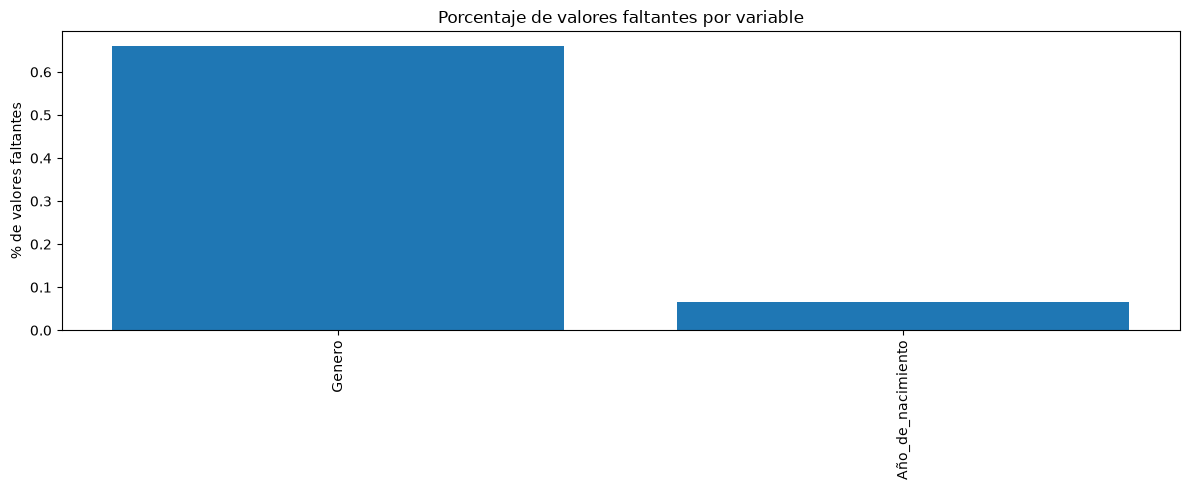

In [18]:
missing = pd.DataFrame({
    "Valores faltantes": df.isna().sum(),
    "% faltantes": df.isna().mean() * 100
})

missing = missing.sort_values(
    by="Valores faltantes",
    ascending=False
)

plt.figure(figsize=(12, 5))

missing_plot = missing[missing["Valores faltantes"] > 0]

if len(missing_plot) > 0:
    plt.bar(
        missing_plot.index,
        missing_plot["% faltantes"]
    )
    plt.xticks(rotation=90)
    plt.ylabel("% de valores faltantes")
    plt.title("Porcentaje de valores faltantes por variable")
    plt.tight_layout()
    plt.show()
else:
    print("No existen valores faltantes en el dataset.")

### Valores duplicados

In [19]:
print(f"Registros duplicados: ", df.duplicated().sum())

Registros duplicados:  758
